In [26]:
import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [27]:
from pathlib import Path
import tarfile

folder = Path("/Users/jessicaliang/Weather Project AISCI 290A/data")
archive = folder / "data.tgz"

print("Archive found:", archive.exists())

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path=folder, filter="data")

print("Extraction complete!")

Archive found: True
Extraction complete!


In [6]:
files = [
    p for p in folder.rglob("*")
    if p.is_file() and p.name != "data.tgz"
]

print("Number of files:", len(files))

for f in files[:10]:
    print(f)

Number of files: 157
/Users/jessicaliang/Weather Project AISCI 290A/data/._data
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2009_JanFeb
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2009_SeptOct
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2010_NovDec
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2010_SeptOct
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2010_MayJune
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2009_MayJune
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2010_JulyAug
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2009_JulyAug
/Users/jessicaliang/Weather Project AISCI 290A/data/data/._2010_JanFeb


In [7]:
%pip install xarray netCDF4

Note: you may need to restart the kernel to use updated packages.


In [8]:
import xarray as xr

nc_files = list(folder.rglob("*.nc"))

print("NetCDF files found:", len(nc_files))

if nc_files:
    ds = xr.open_dataset(nc_files[0])
    display(ds)

NetCDF files found: 120


<xarray.Dataset> Size: 6MB
Dimensions:     (valid_time: 59, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B ...
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 472B 2010-01-01 ... 2010-02-28
Data variables:
    u10         (valid_time, latitude, longitude) float32 6MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T21:04 GRIB to CDM+CF via cfgrib-0.9.1...

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt

folder = Path("/Users/jessicaliang/Weather Project AISCI 290A/data")

temp_files_2009 = sorted([
    p for p in folder.rglob("*2m_temperature*.nc")
    if not p.name.startswith("._")
    and p.parent.name.startswith("2009_")
])

print("Number of files:", len(temp_files_2009))

datasets = [xr.open_dataset(f) for f in temp_files_2009]

ds_2009 = xr.concat(
    datasets,
    dim="valid_time"
).sortby("valid_time")

print(ds_2009)

Number of files: 6
<xarray.Dataset> Size: 36MB
Dimensions:     (valid_time: 365, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 3kB 2009-01-01 ... 2009-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 36MB 274.9 ... 295.5
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...


In [12]:
temp_files_2010 = sorted([
    f for f in nc_files
    if "2010" in str(f)
    and "2m_temperature" in f.name
    and not f.name.startswith("._")
])

lat_seattle = 47.61
lon_seattle = -122.33

temp_2010_parts = []

for f in temp_files_2010:
    with xr.open_dataset(f) as ds:
        s = ds["t2m"].sel(
            latitude=lat_seattle,
            longitude=lon_seattle,
            method="nearest"
        ) - 273.15

        temp_2010_parts.append(s.to_series())

temp_2010 = pd.concat(temp_2010_parts).sort_index()
temp_2010 = temp_2010[~temp_2010.index.duplicated(keep="first")]

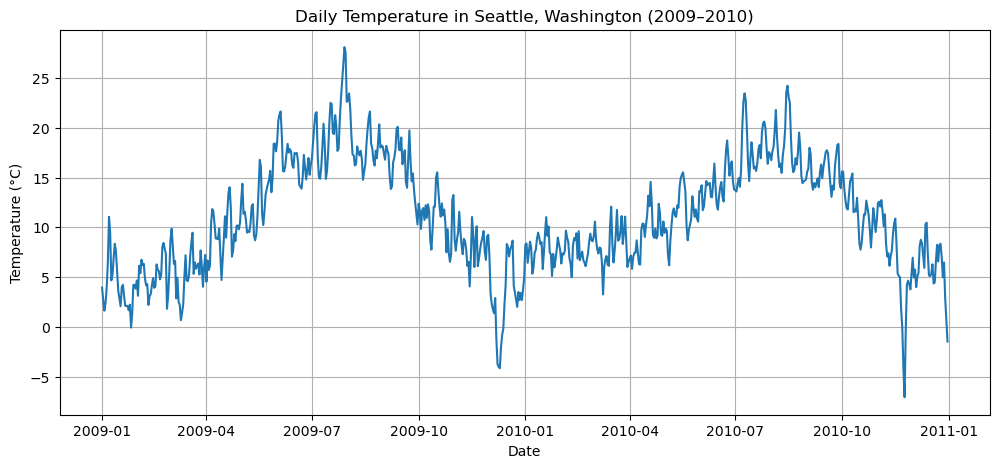

In [14]:
# Seeing whether historical temperature and precipitation data can accurately predict daily temperature and precipitation in Seattle?

T2M_C_2009 = ds_2009["t2m"] - 273.15

T_seattle_2009 = T2M_C_2009.sel(
    latitude=lat_seattle,
    longitude=lon_seattle,
    method="nearest"
)

temperature_both_years = pd.concat([
    T_seattle_2009.to_series(),
    temp_2010
]).sort_index()


plt.figure(figsize=(12, 5))
plt.plot(temperature_both_years.index, temperature_both_years.values)

plt.title("Daily Temperature in Seattle, Washington (2009–2010)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

<xarray.DataArray 't2m' (latitude: 105, longitude: 237)> Size: 100kB
array([[ 2.449768  ,  1.9487    ,  0.52593994, ..., -2.978302  ,
        -1.9802551 , -1.6717529 ],
       [ 2.2879639 ,  2.0523071 ,  2.8874207 , ..., -2.1275635 ,
        -1.9984741 , -1.8518372 ],
       [ 1.454956  ,  2.2610474 ,  3.1016846 , ..., -2.4230347 ,
        -2.3301086 , -2.1907043 ],
       ...,
       [16.093384  , 16.0672    , 16.032196  , ..., 22.766815  ,
        22.782837  , 22.767303  ],
       [16.193481  , 16.172913  , 16.150269  , ..., 22.837372  ,
        22.850891  , 22.835815  ],
       [16.309692  , 16.292542  , 16.276337  , ..., 22.840881  ,
        22.898071  , 22.927307  ]], shape=(105, 237), dtype=float32)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    valid_time  datetime64[ns] 8B 2009-01-05


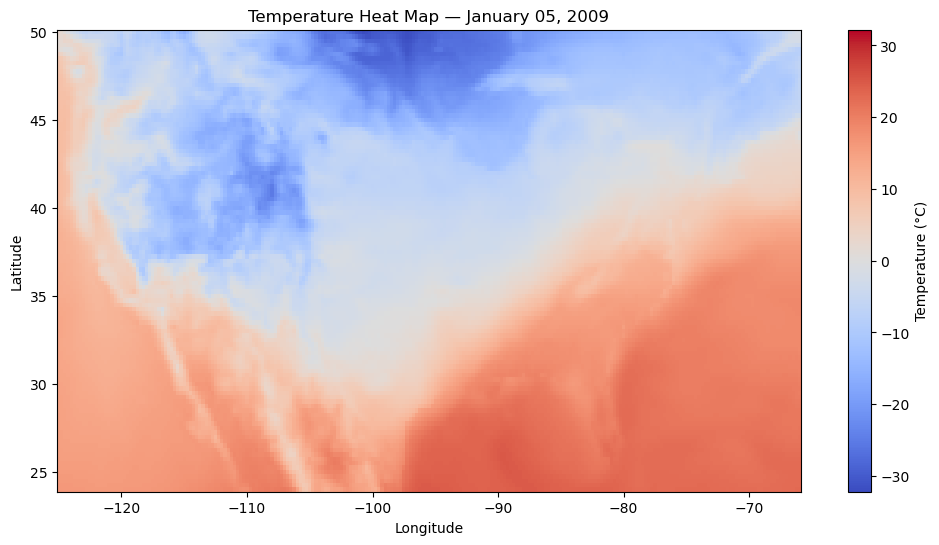

In [17]:
import matplotlib.pyplot as plt

#January 15, 2009
temp_day = ds_2009["t2m"].sel(
    valid_time="2009-01-05"
)

# Convert Kelvin to Celsius
temp_day_C = temp_day - 273.15

print(temp_day_C)

plt.figure(figsize=(12, 6))

temp_day_C.plot(
    x="longitude",
    y="latitude",
    cmap="coolwarm",
    cbar_kwargs={"label": "Temperature (°C)"}
)

plt.title("Temperature Heat Map — January 05, 2009")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [19]:
precip_files_2009 = sorted([
    f for f in nc_files
    if "2009" in str(f)
    and "total_precipitation" in f.name
    and not f.name.startswith("._")
])

precip_2009_parts = []

for f in precip_files_2009:
    with xr.open_dataset(f) as ds:
        s = ds["tp"].sel(
            latitude=lat_seattle,
            longitude=lon_seattle,
            method="nearest"
        )

        precip_2009_parts.append(s.to_series())

precip_2009 = pd.concat(precip_2009_parts).sort_index()
precip_2009 = precip_2009[~precip_2009.index.duplicated(keep="first")]

In [20]:
precip_files_2010 = sorted([
    f for f in nc_files
    if "2010" in str(f)
    and "total_precipitation" in f.name
    and not f.name.startswith("._")
])

precip_2010_parts = []

for f in precip_files_2010:
    with xr.open_dataset(f) as ds:
        s = ds["tp"].sel(
            latitude=lat_seattle,
            longitude=lon_seattle,
            method="nearest"
        )

        precip_2010_parts.append(s.to_series())

precip_2010 = pd.concat(precip_2010_parts).sort_index()
precip_2010 = precip_2010[~precip_2010.index.duplicated(keep="first")]

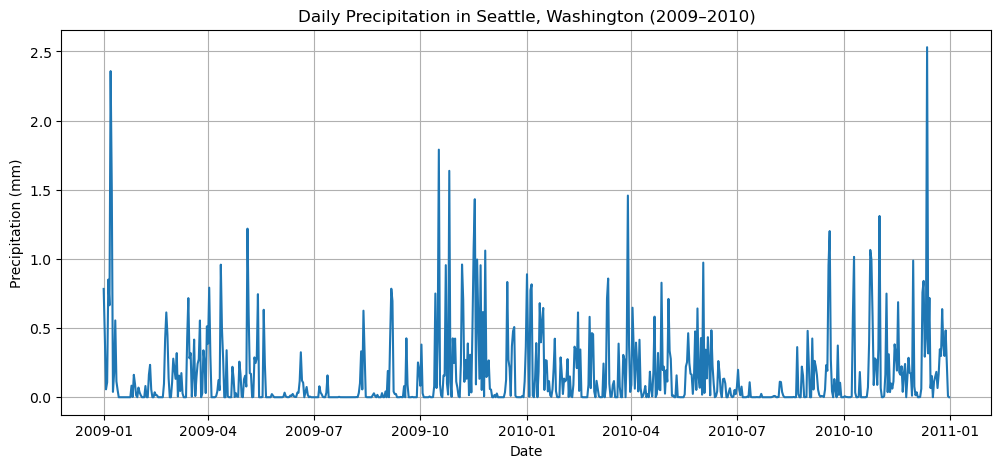

In [21]:
precipitation_both_years = pd.concat([
    precip_2009,
    precip_2010
]).sort_index()

precipitation_both_years = precipitation_both_years[
    ~precipitation_both_years.index.duplicated(keep="first")
]

# Convert meters to millimeters
precipitation_both_years = precipitation_both_years * 1000

plt.figure(figsize=(12, 5))
plt.plot(
    precipitation_both_years.index,
    precipitation_both_years.values
)

plt.title("Daily Precipitation in Seattle, Washington (2009–2010)")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.grid(True)
plt.show()

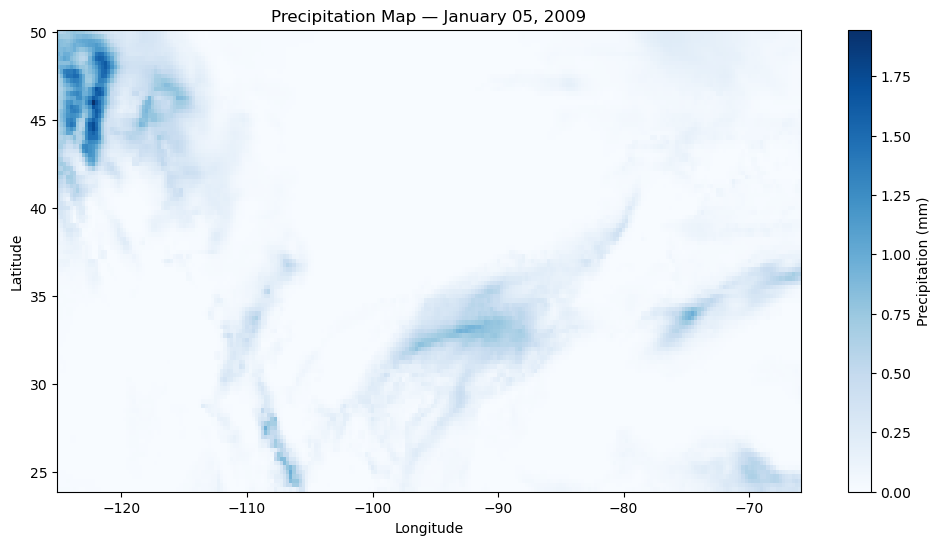

In [22]:
precip_files_2009 = sorted([
    f for f in nc_files
    if "2009" in str(f)
    and "total_precipitation" in f.name
    and not f.name.startswith("._")
]) 

import matplotlib.pyplot as plt
import xarray as xr

with xr.open_dataset(precip_files_2009[0]) as ds_precip:
    # Select precipitation on January 15, 2009
    precip_day = ds_precip["tp"].sel(
        valid_time="2009-01-05"
    ).load()

precip_day_mm = precip_day * 1000

plt.figure(figsize=(12, 6))

precip_day_mm.plot(
    x="longitude",
    y="latitude",
    cmap="Blues",
    cbar_kwargs={"label": "Precipitation (mm)"}
)

plt.title("Precipitation Map — January 05, 2009")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [23]:
weather_focus = T_seattle_2009.to_series().to_frame(name="temp_c") 

In [24]:
precip_files = sorted([
    p for p in folder.rglob("*total_precipitation*.nc")
    if not p.name.startswith("._")
])

precip_list = []

for file in precip_files:
    with xr.open_dataset(file) as ds:
        var = list(ds.data_vars)[0]
        s = ds[var].sel(
            latitude=lat_seattle,
            longitude=lon_seattle,
            method="nearest"
        ).to_series()
        precip_list.append(s)

precipitation = pd.concat(precip_list).sort_index()
precipitation = precipitation[~precipitation.index.duplicated(keep="first")]

weather_focus["precipitation"] = precipitation.reindex(weather_focus.index) * 1000

In [28]:
# Combine 2009 and 2010 temperatures/precipitation
temperature = pd.concat([
    T_seattle_2009.to_series(),
    temp_2010
]).sort_index()

temperature = temperature[~temperature.index.duplicated(keep="first")]
temperature.name = "temp_c"

precipitation = pd.concat([
    precip_2009,
    precip_2010
]).sort_index()

precipitation = precipitation[~precipitation.index.duplicated(keep="first")]
precipitation = precipitation * 1000
precipitation.name = "precipitation"

weather_focus = pd.concat([temperature, precipitation], axis=1)

weather_focus.head()

# I'm creating new features in my model by using average weather/precipitation over 3 day and 7 day period. 

for col in ["temp_c", "precipitation"]:
    weather_focus[f"{col}_3day"] = weather_focus[col].rolling(3).mean()
    weather_focus[f"{col}_7day"] = weather_focus[col].rolling(7).mean()

# Actual next day temperature/precipitation which will be the prediction target 
weather_focus["tomorrow_temp"] = weather_focus["temp_c"].shift(-1)
weather_focus["tomorrow_precip"] = weather_focus["precipitation"].shift(-1)

weather_focus = weather_focus.dropna()

In [29]:
weather_focus.head()

,temp_c,precipitation,temp_c_3day,temp_c_7day,precipitation_3day,precipitation_7day,tomorrow_temp,tomorrow_precip
valid_time,,,,,,,,
2009-01-07,11.054199,2.357443,7.154093,4.585815,1.290851,0.751336,9.439301,1.501779
2009-01-08,9.439301,1.501779,8.997691,5.372044,1.507991,0.854021,4.664490,0.038703
2009-01-09,4.664490,0.038703,8.385997,5.654393,1.299308,0.796843,5.250641,0.173310
2009-01-10,5.250641,0.173310,6.451477,6.173863,0.571264,0.813439,6.912903,0.555038
2009-01-11,6.912903,0.555038,5.609344,6.818516,0.255684,0.877341,8.341248,0.114143


In [87]:
# Train and test a linear regression model (train 2009 data and then test 2010 data)

In [32]:
# This is the baseline model with only today's temperature and precipitation
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Split data into training year (2009) and testing year (2010)
train = weather_focus[weather_focus.index.year == 2009]
test = weather_focus[weather_focus.index.year == 2010]

# Features: today's temperature and precipitation
features = ["temp_c", "precipitation"]

# Predict tomorrow's temperature
model_temp = LinearRegression()
model_temp.fit(train[features], train["tomorrow_temp"])

pred_temp = model_temp.predict(test[features])
temp_mae = mean_absolute_error(test["tomorrow_temp"], pred_temp)

print("Temperature prediction error:", (temp_mae), "°C")

# Predict tomorrow's precipitation
model_precip = LinearRegression()
model_precip.fit(train[features], train["tomorrow_precip"])

pred_precip = model_precip.predict(test[features]).clip(min=0)
precip_mae = mean_absolute_error(test["tomorrow_precip"], pred_precip)

print("Precipitation prediction error:", (precip_mae), "mm")

Temperature prediction error: 1.2246218919754028 °C
Precipitation prediction error: 0.16064918041229248 mm


In [33]:
# This is the expanded model with today's weather and the all other features as shown previously
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Split data into training year (2009) and testing year (2010)
train = weather_focus[weather_focus.index.year == 2009]
test = weather_focus[weather_focus.index.year == 2010]

# Including All Features
features = [
    "temp_c",
    "precipitation",
    "temp_c_3day",
    "temp_c_7day",
    "precipitation_3day",
    "precipitation_7day"
]

# Predict tomorrow's temperature
model_temp = LinearRegression()
model_temp.fit(train[features], train["tomorrow_temp"])

pred_temp = model_temp.predict(test[features])
temp_mae = mean_absolute_error(test["tomorrow_temp"], pred_temp)

print("Temperature prediction error:", (temp_mae), "°C")

# Predict tomorrow's precipitation
model_precip = LinearRegression()
model_precip.fit(train[features], train["tomorrow_precip"])

pred_precip = model_precip.predict(test[features]).clip(min=0)
precip_mae = mean_absolute_error(test["tomorrow_precip"], pred_precip)

print("Precipitation prediction error:", (precip_mae), "mm")

Temperature prediction error: 1.1876705936589973 °C
Precipitation prediction error: 0.1591324824752386 mm


In [34]:
# Now, I will use a more complex model (neural network) to see whether it can improve weather predictions compared to the linear regression

In [35]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

In [37]:
# I am creating a neural network containing only today's weather
train = weather_focus[weather_focus.index.year == 2009].iloc[:-1]
test = weather_focus[weather_focus.index.year == 2010]

features = ["temp_c", "precipitation"]

X_train = train[features]
X_test = test[features]

y_train_temp = train["tomorrow_temp"]
y_test_temp = test["tomorrow_temp"]

y_train_precip = train["tomorrow_precip"]
y_test_precip = test["tomorrow_precip"]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [43]:
nn_temp = MLPRegressor(
    hidden_layer_sizes=(16,8),
    max_iter=3000,
    random_state=42
)

nn_temp.fit(X_train_scaled, y_train_temp)

nn_pred_temp = nn_temp.predict(X_test_scaled)

nn_temp_mae = mean_absolute_error(y_test_temp, nn_pred_temp)

print("Neural network temperature error:", nn_temp_mae, "°C")

nn_precip = MLPRegressor(
    hidden_layer_sizes=(16,8),
    max_iter=3000,
    random_state=42
)

nn_precip.fit(X_train_scaled, y_train_precip)

nn_pred_precip = nn_precip.predict(X_test_scaled).clip(min=0)

nn_precip_mae = mean_absolute_error(y_test_precip, nn_pred_precip)

print("Neural network precipitation error:", nn_precip_mae, "mm")

Neural network temperature error: 1.2167936563491821 °C
Neural network precipitation error: 0.1742597371339798 mm


In [46]:
# I am creating a neural network containing today's weather + 3-day/7-day rolling averages
train = weather_focus[weather_focus.index.year == 2009].iloc[:-1]
test = weather_focus[weather_focus.index.year == 2010]

features = features = [
    "temp_c",
    "precipitation",
    "temp_c_3day",
    "temp_c_7day",
    "precipitation_3day",
    "precipitation_7day"
]

X_train = train[features]
X_test = test[features]

y_train_temp = train["tomorrow_temp"]
y_test_temp = test["tomorrow_temp"]

y_train_precip = train["tomorrow_precip"]
y_test_precip = test["tomorrow_precip"]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
nn_temp = MLPRegressor(
    hidden_layer_sizes=(16,8),
    max_iter=3000,
    random_state=42
)

nn_temp.fit(X_train_scaled, y_train_temp)

nn_pred_temp = nn_temp.predict(X_test_scaled)

nn_temp_mae = mean_absolute_error(y_test_temp, nn_pred_temp)

print("Expanded neural network temperature error:", nn_temp_mae, "°C")

nn_precip = MLPRegressor(
    hidden_layer_sizes=(10,),
    max_iter=3000,
    random_state=42
)

nn_precip.fit(X_train_scaled, y_train_precip)

nn_pred_precip = nn_precip.predict(X_test_scaled).clip(min=0)

nn_precip_mae = mean_absolute_error(y_test_precip, nn_pred_precip)

print("Expanded neural network precipitation error:", nn_precip_mae, "mm")

Expanded neural network temperature error: 1.2518114629406103 °C
Expanded neural network precipitation error: 0.18419842431161032 mm
